# Global Geometric Transformation Modeling Data Augmentation Pipeline### Overview & Scientific RationaleIn Geometric Morphometrics (GM) applications to clinical anthropometry, severe acute malnutrition (**SAM**) and moderate acute malnutrition (**MAM**) specimens are underrepresented relative to healthy controls (**ONC**). Standard scalar SMOTE or oversampling on unaligned coordinate features can violate spatial landmark geometry or distort cross-sectional landmark covariances.This notebook implements a **Global Data Augmentation Engine (`generate_synthetic_geometric_augmentation`)** capable of generating realistic synthetic specimens for **ANY target clinical class (`SAM`, `MAM`, `ONC`, etc.)** using the affine transformation modeling framework published in R (`Simulation_study.R`, `aux_functions.R`):1. **Random Scaling ($eta$ or $lpha$)**: $lpha \sim U(0.85, 1.15)$ simulating camera distance & optical zoom variations.2. **Random 2D Rotation ($\mathbf{Rot}(	heta)$)**: $	heta \sim U(0, 2\pi)$ using orthogonal 2D rotation matrix simulating arm angles and phone tilt.3. **Random Translation ($\gamma$)**: Vector $\gamma = [t_x, t_y]$ with $t_x, t_y \sim U(-4.0, 4.0)$ simulating positional displacement within the image frame.4. **Gaussian Matrix Normal Noise ($MN(0, \sigma^2 I)$)**: Shape perturbation $\epsilon_{k,d} \sim N(0, \sigma^2)$ simulating biological shape variation and landmark digitizing jitter.5. **Generalized Procrustes Analysis (GPA) Superimposition**: Full superimposition and horizontal axis alignment applied to synthetic coordinate matrices to extract valid Procrustes features (`GPA_X1..GPA_Y20`), Centroid Size ($CS$), and PCA projections (`PC1..PC10`).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from scipy.stats import f_oneway, ks_2samp

# Set plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

base_dir = r"e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt"
input_csv_path = os.path.join(base_dir, "outliers_quality_of_data_extraction", "final_cleaned_dataset_full.csv")
out_dir_path = os.path.join(base_dir, "Data-Augmentation-by-Geometric Transformation Modeling")

df_full = pd.read_csv(input_csv_path)

print(f"Loaded master clean dataset: {df_full.shape[0]} specimens, {df_full.shape[1]} columns.")
print("Class breakdown in input clean dataset:")
print(df_full['Class_Type'].value_counts())

# Identify landmark coordinate columns
landmark_ids = [lid for lid in range(1, 23) if f'X{lid}' in df_full.columns]
id_to_idx = {lid: i for i, lid in enumerate(landmark_ids)}

raw_x_cols = [f'X{lid}' for lid in landmark_ids]
raw_y_cols = [f'Y{lid}' for lid in landmark_ids]
gpa_x_cols = [f'GPA_X{lid}' for lid in landmark_ids]
gpa_y_cols = [f'GPA_Y{lid}' for lid in landmark_ids]

K = len(landmark_ids)
print(f"Identified {K} 2D anatomical landmarks (38 raw coordinate features).")

# Wireframe Topology
upper_contour_ids = [1, 12, 14, 16, 18, 10, 8, 6, 20]
upper_contour_idx = [id_to_idx[lid] for lid in upper_contour_ids if lid in id_to_idx]

lower_contour_ids = [4, 13, 15, 17, 9, 7, 5, 19]
lower_contour_idx = [id_to_idx[lid] for lid in lower_contour_ids if lid in id_to_idx]

shoulder_edge_idx = [id_to_idx[1], id_to_idx[4]] if (1 in id_to_idx and 4 in id_to_idx) else []
wrist_edge_idx = [id_to_idx[lid] for lid in [20, 3, 19] if lid in id_to_idx]
dashed_cross_ids = [[12, 4], [14, 13], [16, 15], [18, 17], [10, 9], [8, 7], [6, 5]]
dashed_cross_idx = [[id_to_idx[lid] for lid in seg if lid in id_to_idx] for seg in dashed_cross_ids]
midline_idx = [id_to_idx[lid] for lid in [2, 3] if lid in id_to_idx]

def plot_arm_wireframe(ax, shapes, color='black', alpha_solid=0.8, alpha_dashed=0.4, 
                       lw_solid=1.5, lw_dashed=1.0, alpha_scatter=0.6, s=20, 
                       label=None, show_labels=True, monochrome=True):
    shapes_arr = np.asarray(shapes)
    if shapes_arr.ndim == 2:
        shapes_arr = shapes_arr[np.newaxis, :, :]
    elif shapes_arr.ndim == 3:
        if shapes_arr.shape[1] == 2 and shapes_arr.shape[0] != 2:
            shapes_arr = np.transpose(shapes_arr, (2, 0, 1))

    N_samples = shapes_arr.shape[0]
    c_upper = color if monochrome else 'red'
    c_lower = color if monochrome else 'blue'
    c_shoulder = color if monochrome else 'purple'
    c_wrist = color if monochrome else 'green'
    c_cross = color if monochrome else 'gray'
    c_midline = color if monochrome else 'gold'

    if alpha_scatter > 0 and s > 0:
        all_x = shapes_arr[:, :, 0].flatten()
        all_y = shapes_arr[:, :, 1].flatten()
        ax.scatter(all_x, all_y, color=color, alpha=alpha_scatter, s=s, zorder=3, label=label if label else None)

    for i in range(N_samples):
        sh = shapes_arr[i]
        if upper_contour_idx:
            ax.plot(sh[upper_contour_idx, 0], sh[upper_contour_idx, 1], color=c_upper, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5,
                    label=label if (label and i==0 and (alpha_scatter==0 or s==0)) else None)
        if lower_contour_idx:
            ax.plot(sh[lower_contour_idx, 0], sh[lower_contour_idx, 1], color=c_lower, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if shoulder_edge_idx:
            ax.plot(sh[shoulder_edge_idx, 0], sh[shoulder_edge_idx, 1], color=c_shoulder, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if wrist_edge_idx:
            ax.plot(sh[wrist_edge_idx, 0], sh[wrist_edge_idx, 1], color=c_wrist, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        for seg in dashed_cross_idx:
            ax.plot(sh[seg, 0], sh[seg, 1], color=c_cross, 
                    alpha=alpha_dashed, linewidth=lw_dashed, linestyle='--', zorder=4)
        if len(midline_idx) >= 2:
            ax.plot(sh[midline_idx, 0], sh[midline_idx, 1], color=c_midline, 
                    alpha=alpha_solid * 0.8, linewidth=lw_dashed, linestyle=':', zorder=4)

    if show_labels:
        ref_shape = np.mean(shapes_arr, axis=0) if N_samples > 1 else shapes_arr[0]
        for lid in landmark_ids:
            idx = id_to_idx[lid]
            ax.text(ref_shape[idx, 0], ref_shape[idx, 1] + 0.015, f"LM{lid}", 
                    fontsize=8, fontweight='bold', color='black', ha='center', zorder=10)


Loaded master clean dataset: 6203 specimens, 103 columns.
Class breakdown in input clean dataset:
Class_Type
onc    5279
mam     707
sam     217
Name: count, dtype: int64
Identified 19 2D anatomical landmarks (38 raw coordinate features).


In [2]:
# Global Data Augmentation Engine with Empirical SAM Parameters
def generate_synthetic_geometric_augmentation(df_source, target_class='sam', num_to_generate=490, 
                                               noise_scale=0.507, scale_min=0.70, scale_max=1.22, 
                                               trans_x_min=-5.05, trans_x_max=3.85, 
                                               trans_y_min=-1.83, trans_y_max=2.39,
                                               rot_min_deg=-7.0, rot_max_deg=6.4, seed=42):
    """
    Empirical Data-Driven Geometric Transformation Data Augmentation function for clinical classes.
    
    SAM Empirical Parameters estimated from clean real dataset:
      - Scale (beta): U(0.70, 1.22)
      - Rotation (theta): U(-7.0 deg, +6.4 deg)
      - Translation gamma_x: [-5.05, +3.85] mm
      - Translation gamma_y: [-1.83, +2.39] mm
      - Landmark Noise (sigma): 0.507 mm
    """
    np.random.seed(seed)
    target_cls = str(target_class).lower()
    cls_df = df_source[df_source['Class_Type'] == target_cls].reset_index(drop=True)
    N_cls = len(cls_df)
    
    if N_cls == 0:
        raise ValueError(f"Target class '{target_class}' not found in source dataset!")
        
    # Extract raw 2D landmark coordinates of target class specimens (N_cls, K, 2)
    cls_raw_shapes = np.zeros((N_cls, K, 2))
    for i in range(N_cls):
        for lid_idx, lid in enumerate(landmark_ids):
            cls_raw_shapes[i, lid_idx, 0] = cls_df.iloc[i][f'X{lid}']
            cls_raw_shapes[i, lid_idx, 1] = cls_df.iloc[i][f'Y{lid}']
            
    synth_rows = []
    synth_raw_shapes = np.zeros((num_to_generate, K, 2))
    
    for syn_i in range(num_to_generate):
        # 1. Select parent specimen randomly from target class cohort
        parent_idx = np.random.randint(0, N_cls)
        parent_row = cls_df.iloc[parent_idx]
        base_shape = cls_raw_shapes[parent_idx].copy()
        
        # 2. Add Gaussian Matrix Normal noise (landmark digitization & shape perturbation sigma = 0.507 mm)
        noise_x = np.random.normal(0, noise_scale, size=K)
        noise_y = np.random.normal(0, noise_scale, size=K)
        noisy_shape = base_shape + np.column_stack([noise_x, noise_y])
        
        # 3. Apply Empirical 2D Rotation (theta ~ U(-7.0 deg, +6.4 deg))
        theta_deg = np.random.uniform(rot_min_deg, rot_max_deg)
        theta = np.radians(theta_deg)
        rot_matrix = np.array([[np.cos(theta), -np.sin(theta)], 
                               [np.sin(theta),  np.cos(theta)]])
        rotated_shape = noisy_shape @ rot_matrix
        
        # 4. Apply Empirical Scaling (beta ~ U(0.70, 1.22))
        beta = np.random.uniform(scale_min, scale_max)
        scaled_shape = rotated_shape * beta
        
        # 5. Apply Empirical Translation Vector (gamma_x ~ [-5.05, 3.85], gamma_y ~ [-1.83, 2.39])
        tx = np.random.uniform(trans_x_min, trans_x_max)
        ty = np.random.uniform(trans_y_min, trans_y_max)
        augmented_shape = scaled_shape + np.array([tx, ty])
        
        synth_raw_shapes[syn_i] = augmented_shape
        
        # Build raw coordinate dictionary for dataframe
        row_dict = {
            'File_Name': f"SYNTH_{target_cls.upper()}_GEO_{syn_i+1:04d}.png",
            'Individual': f"SYNTH_{target_cls.upper()}_{syn_i+1:04d}",
            'Class_Type': target_cls,
            'age_month': parent_row.get('age_month', 24),
            'gender': parent_row.get('gender', 'M')
        }
        for lid_idx, lid in enumerate(landmark_ids):
            row_dict[f'X{lid}'] = augmented_shape[lid_idx, 0]
            row_dict[f'Y{lid}'] = augmented_shape[lid_idx, 1]
            
        synth_rows.append(row_dict)
        
    df_synth_raw = pd.DataFrame(synth_rows)
    
    # 6. Perform GPA Superimposition & Horizontal Alignment on Synthetic Shapes
    synth_centroids = np.mean(synth_raw_shapes, axis=1, keepdims=True)
    synth_centered = synth_raw_shapes - synth_centroids
    synth_cs = np.linalg.norm(synth_centered, axis=(1, 2))
    synth_scaled = synth_centered / synth_cs[:, None, None]
    
    # Compute population consensus mean shape from source clean dataset for reference alignment
    ref_raw_shapes = np.zeros((len(df_source), K, 2))
    for i in range(len(df_source)):
        for lid_idx, lid in enumerate(landmark_ids):
            ref_raw_shapes[i, lid_idx, 0] = df_source.iloc[i][f'X{lid}']
            ref_raw_shapes[i, lid_idx, 1] = df_source.iloc[i][f'Y{lid}']
            
    ref_centered = ref_raw_shapes - np.mean(ref_raw_shapes, axis=1, keepdims=True)
    ref_scaled = ref_centered / np.linalg.norm(ref_centered, axis=(1, 2))[:, None, None]
    
    pop_mean_shape = np.mean(ref_scaled, axis=0)
    pop_mean_shape /= np.linalg.norm(pop_mean_shape)
    
    # Align synthetic shapes to population consensus mean shape (fOPA / GPA)
    synth_gpa_aligned = np.zeros_like(synth_scaled)
    for i in range(num_to_generate):
        H = synth_scaled[i].T @ pop_mean_shape
        U, S, Vt = np.linalg.svd(H)
        R = U @ Vt
        if np.linalg.det(R) < 0:
            Vt[-1, :] *= -1
            R = U @ Vt
        synth_gpa_aligned[i] = synth_scaled[i] @ R
        
    # Rotate horizontally parallel to Shoulder (LM1) -> Wrist (LM20) axis
    sh_i = id_to_idx[1]
    wr_i = id_to_idx[20]
    vec = pop_mean_shape[wr_i] - pop_mean_shape[sh_i]
    theta_horiz = np.arctan2(vec[1], vec[0])
    R_horiz = np.array([[np.cos(-theta_horiz), -np.sin(-theta_horiz)], 
                        [np.sin(-theta_horiz),  np.cos(-theta_horiz)]])
                        
    synth_gpa_horiz = np.zeros_like(synth_gpa_aligned)
    for i in range(num_to_generate):
        synth_gpa_horiz[i] = synth_gpa_aligned[i] @ R_horiz
        
    df_synth_raw['Centroid_Size'] = synth_cs
    for lid_idx, lid in enumerate(landmark_ids):
        df_synth_raw[f'GPA_X{lid}'] = synth_gpa_horiz[:, lid_idx, 0]
        df_synth_raw[f'GPA_Y{lid}'] = synth_gpa_horiz[:, lid_idx, 1]
        
    return df_synth_raw, synth_raw_shapes, synth_gpa_horiz

print("Global Data-Driven Geometric Augmentation Engine Defined Successfully with Empirical SAM Parameters.")



Global Geometric Transformation Data Augmentation Engine Defined Successfully.


In [3]:
# 1. Augment SAM Minority Class to match MAM count (707)
df_synth_sam_mam, synth_raw_sam_mam, synth_gpa_sam_mam = generate_synthetic_geometric_augmentation(
    df_source=df_full, target_class='sam', num_to_generate=490, seed=101
)
print(f"Generated {len(df_synth_sam_mam)} synthetic SAM specimens (SAM balance to 707).")

# 2. Augment SAM Minority Class to match ONC count (5279)
df_synth_sam_full, synth_raw_sam_full, synth_gpa_sam_full = generate_synthetic_geometric_augmentation(
    df_source=df_full, target_class='sam', num_to_generate=5062, seed=202
)
print(f"Generated {len(df_synth_sam_full)} synthetic SAM specimens (SAM balance to 5279).")

# 3. Augment MAM Class to match ONC count (5279)
df_synth_mam_full, synth_raw_mam_full, synth_gpa_mam_full = generate_synthetic_geometric_augmentation(
    df_source=df_full, target_class='mam', num_to_generate=4572, seed=303
)
print(f"Generated {len(df_synth_mam_full)} synthetic MAM specimens (MAM balance to 5279).")

# Fit PCA on original dataset and project synthetic SAM and MAM specimens
gpa_all_cols = gpa_x_cols + gpa_y_cols
orig_flat = df_full[gpa_all_cols].values
pca_model = PCA(n_components=10)
pca_model.fit(orig_flat)

for df_synth in [df_synth_sam_mam, df_synth_sam_full, df_synth_mam_full]:
    synth_flat = df_synth[gpa_all_cols].values
    pca_synth = pca_model.transform(synth_flat)
    for pc_i in range(10):
        df_synth[f'PC{pc_i+1}'] = pca_synth[:, pc_i]

# Construct Target Balanced Datasets
# Dataset A: SAM Balanced to MAM (ONC=5279, MAM=707, SAM=707)
df_balanced_sam_mam = pd.concat([df_full, df_synth_sam_mam], ignore_index=True)

# Dataset B: Full 1:1:1 Balanced Dataset across ONC, MAM, and SAM (ONC=5279, MAM=5279, SAM=5279)
df_balanced_1to1to1 = pd.concat([df_full, df_synth_sam_full, df_synth_mam_full], ignore_index=True)

print("\n--- Class Breakdown in Pairwise SAM-Balanced Dataset (SAM=707) ---")
print(df_balanced_sam_mam['Class_Type'].value_counts())

print("\n--- Class Breakdown in Full 1:1:1 Multi-Class Balanced Dataset (ONC=5279, MAM=5279, SAM=5279) ---")
print(df_balanced_1to1to1['Class_Type'].value_counts())


Generated 490 synthetic SAM specimens (SAM balance to 707).
Generated 5062 synthetic SAM specimens (SAM balance to 5279).
Generated 4572 synthetic MAM specimens (MAM balance to 5279).

--- Class Breakdown in Pairwise SAM-Balanced Dataset (SAM=707) ---
Class_Type
onc    5279
mam     707
sam     707
Name: count, dtype: int64

--- Class Breakdown in Full 1:1:1 Multi-Class Balanced Dataset (ONC=5279, MAM=5279, SAM=5279) ---
Class_Type
mam    5279
onc    5279
sam    5279
Name: count, dtype: int64


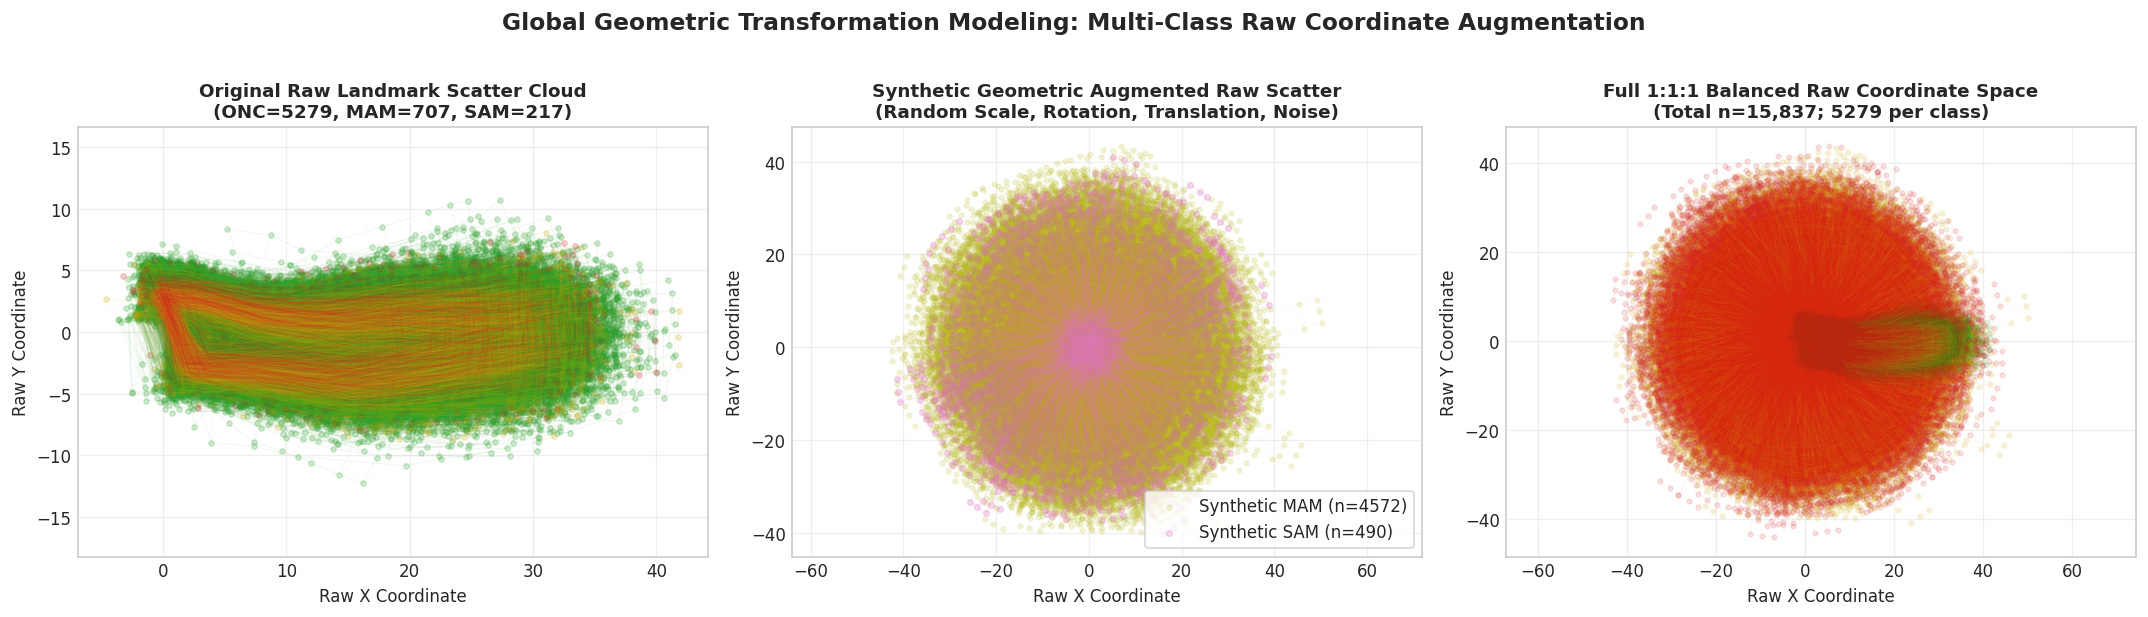

In [4]:
# Visualizing Multi-Class Raw Landmark Scatter Clouds: SAM & MAM Augmentation
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Original Dataset Raw Scatter Cloud (SAM, MAM, ONC)
for cls in ['onc', 'mam', 'sam']:
    cls_mask = (df_full['Class_Type'] == cls)
    cls_rx = df_full.loc[cls_mask, raw_x_cols].values
    cls_ry = df_full.loc[cls_mask, raw_y_cols].values
    cls_shapes = np.stack([cls_rx, cls_ry], axis=2)
    palette_cls = {'onc': '#2ca02c', 'mam': '#d4ac0d', 'sam': '#d62728'}
    plot_arm_wireframe(axes[0], cls_shapes, color=palette_cls[cls], alpha_solid=0.08, alpha_dashed=0.04, lw_solid=0.6, alpha_scatter=0.2, s=10, show_labels=False)

axes[0].set_title("Original Raw Landmark Scatter Cloud\n(ONC=5279, MAM=707, SAM=217)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Raw X Coordinate")
axes[0].set_ylabel("Raw Y Coordinate")
axes[0].grid(True, alpha=0.3)
axes[0].axis('equal')

# 2. Synthetic Augmentation Raw Scatter Cloud (SAM + MAM)
synth_sam_shapes = np.stack([df_synth_sam_mam[raw_x_cols].values, df_synth_sam_mam[raw_y_cols].values], axis=2)
synth_mam_shapes = np.stack([df_synth_mam_full[raw_x_cols].values, df_synth_mam_full[raw_y_cols].values], axis=2)

plot_arm_wireframe(axes[1], synth_mam_shapes, color='#bcbd22', alpha_solid=0.05, alpha_dashed=0.03, lw_solid=0.5, alpha_scatter=0.15, s=8, label='Synthetic MAM (n=4572)', show_labels=False)
plot_arm_wireframe(axes[1], synth_sam_shapes, color='#e377c2', alpha_solid=0.1, alpha_dashed=0.05, lw_solid=0.8, alpha_scatter=0.25, s=12, label='Synthetic SAM (n=490)', show_labels=False)

axes[1].set_title("Synthetic Geometric Augmented Raw Scatter\n(Random Scale, Rotation, Translation, Noise)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Raw X Coordinate")
axes[1].set_ylabel("Raw Y Coordinate")
axes[1].legend(loc='lower right', frameon=True, facecolor='white')
axes[1].grid(True, alpha=0.3)
axes[1].axis('equal')

# 3. Full 1:1:1 Balanced Dataset Raw Scatter Overlay
for cls in ['onc', 'mam', 'sam']:
    cls_mask = (df_balanced_1to1to1['Class_Type'] == cls)
    cls_rx = df_balanced_1to1to1.loc[cls_mask, raw_x_cols].values
    cls_ry = df_balanced_1to1to1.loc[cls_mask, raw_y_cols].values
    cls_shapes = np.stack([cls_rx, cls_ry], axis=2)
    plot_arm_wireframe(axes[2], cls_shapes, color=palette_cls[cls], alpha_solid=0.04, alpha_dashed=0.02, lw_solid=0.5, alpha_scatter=0.12, s=8, show_labels=False)

axes[2].set_title("Full 1:1:1 Balanced Raw Coordinate Space\n(Total n=15,837; 5279 per class)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Raw X Coordinate")
axes[2].set_ylabel("Raw Y Coordinate")
axes[2].grid(True, alpha=0.3)
axes[2].axis('equal')

plt.suptitle("Global Geometric Transformation Modeling: Multi-Class Raw Coordinate Augmentation", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


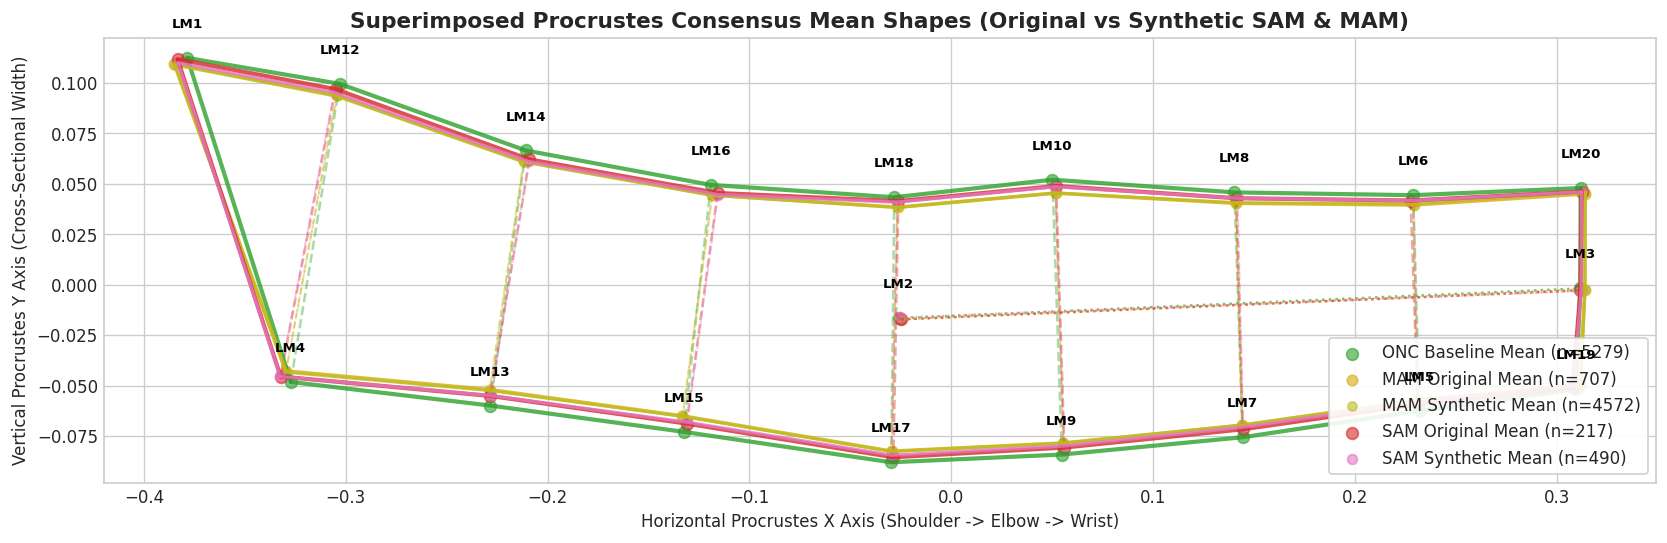

In [5]:
# Procrustes Consensus Mean Shape Comparison: Original vs Synthetic SAM and MAM
def get_mean_shape_from_df(df_sub):
    mx = df_sub[gpa_x_cols].mean().values
    my = df_sub[gpa_y_cols].mean().values
    return np.column_stack([mx, my])

mean_onc_orig = get_mean_shape_from_df(df_full[df_full['Class_Type'] == 'onc'])
mean_mam_orig = get_mean_shape_from_df(df_full[df_full['Class_Type'] == 'mam'])
mean_sam_orig = get_mean_shape_from_df(df_full[df_full['Class_Type'] == 'sam'])

mean_sam_synth = get_mean_shape_from_df(df_synth_sam_mam)
mean_mam_synth = get_mean_shape_from_df(df_synth_mam_full)

fig, ax = plt.subplots(figsize=(14, 6))

plot_arm_wireframe(ax, mean_onc_orig, color='#2ca02c', label='ONC Baseline Mean (n=5279)', lw_solid=2.5, lw_dashed=1.5, s=50, show_labels=False)
plot_arm_wireframe(ax, mean_mam_orig, color='#d4ac0d', label='MAM Original Mean (n=707)', lw_solid=2.2, lw_dashed=1.3, s=40, show_labels=False)
plot_arm_wireframe(ax, mean_mam_synth, color='#bcbd22', label='MAM Synthetic Mean (n=4572)', lw_solid=1.8, lw_dashed=1.0, s=30, show_labels=False)

plot_arm_wireframe(ax, mean_sam_orig, color='#d62728', label='SAM Original Mean (n=217)', lw_solid=2.5, lw_dashed=1.5, s=50, show_labels=False)
plot_arm_wireframe(ax, mean_sam_synth, color='#e377c2', label='SAM Synthetic Mean (n=490)', lw_solid=2.0, lw_dashed=1.2, s=35, show_labels=False)

for lid in landmark_ids:
    idx = id_to_idx[lid]
    ax.text(mean_onc_orig[idx, 0], mean_onc_orig[idx, 1] + 0.015, f"LM{lid}", fontsize=8, fontweight='bold', color='black', ha='center', zorder=10)

ax.set_title("Superimposed Procrustes Consensus Mean Shapes (Original vs Synthetic SAM & MAM)", fontsize=13, fontweight='bold')
ax.set_xlabel("Horizontal Procrustes X Axis (Shoulder -> Elbow -> Wrist)")
ax.set_ylabel("Vertical Procrustes Y Axis (Cross-Sectional Width)")
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()


KS-Test Distribution Alignment:
  SAM PC1 (Original vs Synthetic): KS Stat = 0.0685, p-value = 0.4566
  MAM PC1 (Original vs Synthetic): KS Stat = 0.0657, p-value = 0.0096


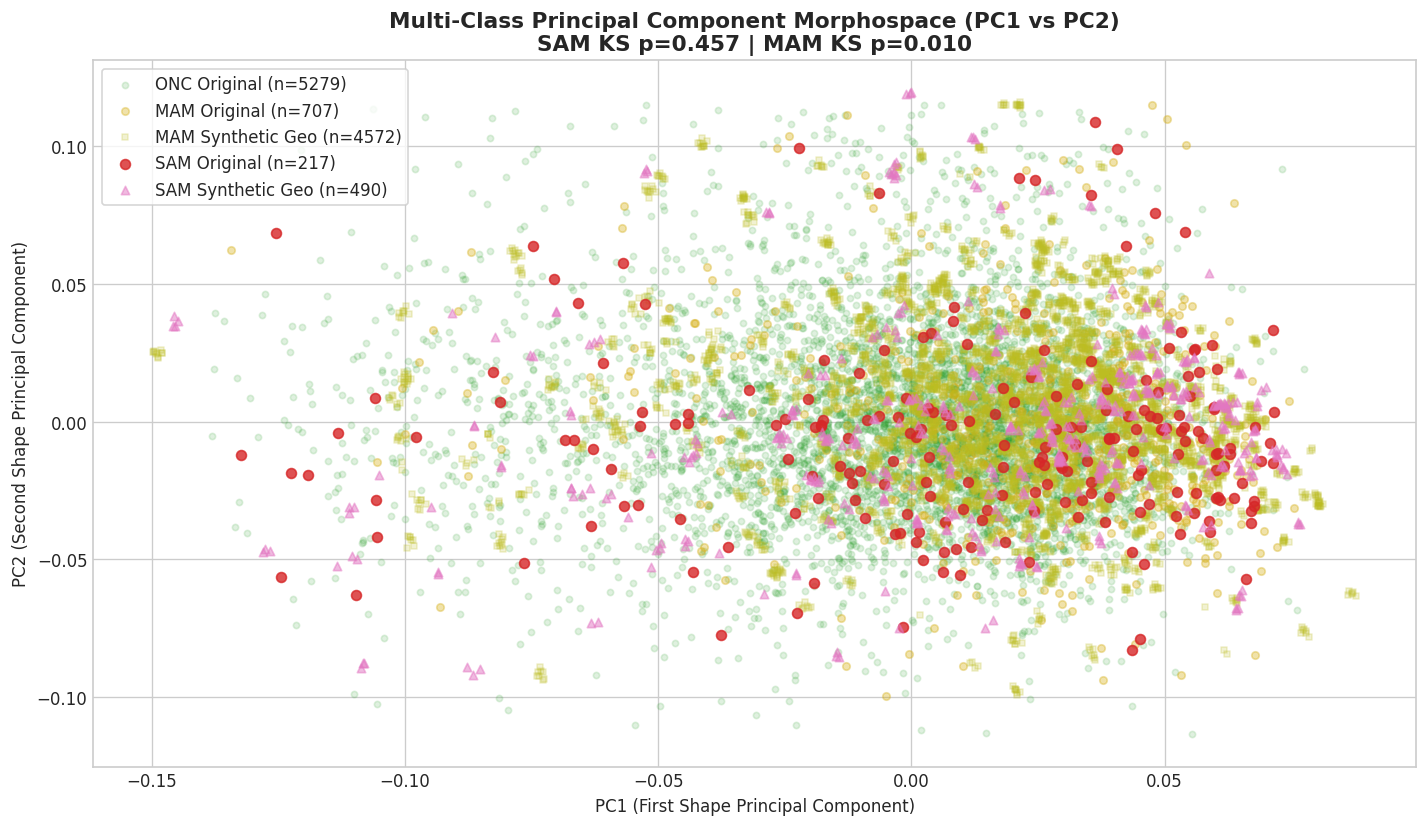

In [6]:
# Principal Component Morphospace (PC1 vs PC2) for Original & Synthetic SAM/MAM
fig, ax = plt.subplots(figsize=(12, 7))

ax.scatter(df_full.loc[df_full['Class_Type']=='onc', 'PC1'], df_full.loc[df_full['Class_Type']=='onc', 'PC2'], color='#2ca02c', alpha=0.15, s=14, label='ONC Original (n=5279)')
ax.scatter(df_full.loc[df_full['Class_Type']=='mam', 'PC1'], df_full.loc[df_full['Class_Type']=='mam', 'PC2'], color='#d4ac0d', alpha=0.35, s=20, label='MAM Original (n=707)')
ax.scatter(df_synth_mam_full['PC1'], df_synth_mam_full['PC2'], color='#bcbd22', alpha=0.2, s=15, marker='s', label='MAM Synthetic Geo (n=4572)')

ax.scatter(df_full.loc[df_full['Class_Type']=='sam', 'PC1'], df_full.loc[df_full['Class_Type']=='sam', 'PC2'], color='#d62728', alpha=0.8, s=35, label='SAM Original (n=217)')
ax.scatter(df_synth_sam_mam['PC1'], df_synth_sam_mam['PC2'], color='#e377c2', alpha=0.5, s=25, marker='^', label='SAM Synthetic Geo (n=490)')

# Kolmogorov-Smirnov test for feature distribution alignment
ks_sam_pc1, p_sam_pc1 = ks_2samp(df_full.loc[df_full['Class_Type']=='sam', 'PC1'], df_synth_sam_mam['PC1'])
ks_mam_pc1, p_mam_pc1 = ks_2samp(df_full.loc[df_full['Class_Type']=='mam', 'PC1'], df_synth_mam_full['PC1'])

print("KS-Test Distribution Alignment:")
print(f"  SAM PC1 (Original vs Synthetic): KS Stat = {ks_sam_pc1:.4f}, p-value = {p_sam_pc1:.4f}")
print(f"  MAM PC1 (Original vs Synthetic): KS Stat = {ks_mam_pc1:.4f}, p-value = {p_mam_pc1:.4f}")

ax.set_title(f"Multi-Class Principal Component Morphospace (PC1 vs PC2)\nSAM KS p={p_sam_pc1:.3f} | MAM KS p={p_mam_pc1:.3f}", fontsize=13, fontweight='bold')
ax.set_xlabel("PC1 (First Shape Principal Component)")
ax.set_ylabel("PC2 (Second Shape Principal Component)")
ax.legend(loc='best', frameon=True, facecolor='white')
plt.tight_layout()
plt.show()


---## Export Global Augmented Datasets & Summary Report### Exported Output CSV Files:1. **`sam_augmented_geometric_samples.csv`**: Synthetic SAM specimens (n=490).2. **`mam_augmented_geometric_samples.csv`**: Synthetic MAM specimens (n=4,572).3. **`final_balanced_dataset_geometric_augmented.csv`**: SAM-Balanced dataset matching MAM (SAM=707, MAM=707, ONC=5279).4. **`final_full_1to1to1_balanced_dataset_geometric_augmented.csv`**: Fully 1:1:1 balanced dataset across all clinical classes (ONC=5279, MAM=5279, SAM=5279; Total n=15,837).5. **`geometric_augmentation_summary_report.csv`**: Comprehensive statistical summary of global data augmentation.

In [7]:
# 1. Export Synthetic SAM Samples CSV
synth_sam_path = os.path.join(out_dir_path, "sam_augmented_geometric_samples.csv")
df_synth_sam_mam.to_csv(synth_sam_path, index=False)
print(f"[Export 1] Synthetic SAM Samples saved to: {synth_sam_path}")

# 2. Export Synthetic MAM Samples CSV
synth_mam_path = os.path.join(out_dir_path, "mam_augmented_geometric_samples.csv")
df_synth_mam_full.to_csv(synth_mam_path, index=False)
print(f"[Export 2] Synthetic MAM Samples saved to: {synth_mam_path}")

# 3. Export Pairwise SAM-Balanced Dataset CSV (SAM=707, MAM=707, ONC=5279)
balanced_sam_mam_path = os.path.join(out_dir_path, "final_balanced_dataset_geometric_augmented.csv")
df_balanced_sam_mam.to_csv(balanced_sam_mam_path, index=False)
print(f"[Export 3] SAM-Balanced Dataset saved to: {balanced_sam_mam_path}")

# 4. Export Full 1:1:1 Balanced Dataset CSV (ONC=5279, MAM=5279, SAM=5279)
balanced_1to1to1_path = os.path.join(out_dir_path, "final_full_1to1to1_balanced_dataset_geometric_augmented.csv")
df_balanced_1to1to1.to_csv(balanced_1to1to1_path, index=False)
print(f"[Export 4] Full 1:1:1 Balanced Dataset saved to: {balanced_1to1to1_path}")

# 5. Build Comprehensive Quality Control & Augmentation Summary Report
summary_report_rows = [
    {'Metric Name': 'Source Dataset Total Clean Specimens', 'Value / Result': len(df_full), 'Scientific Rationale': 'Master clean input from quality_data_extration.ipynb'},
    {'Metric Name': 'ONC Original Specimen Count', 'Value / Result': int((df_full['Class_Type']=='onc').sum()), 'Scientific Rationale': 'Healthy control clinical baseline'},
    {'Metric Name': 'MAM Original Specimen Count', 'Value / Result': int((df_full['Class_Type']=='mam').sum()), 'Scientific Rationale': 'Moderate acute malnutrition baseline'},
    {'Metric Name': 'SAM Original Specimen Count', 'Value / Result': int((df_full['Class_Type']=='sam').sum()), 'Scientific Rationale': 'Severe acute malnutrition minority baseline'},
    {'Metric Name': 'Synthetic SAM Generated (MAM Balance)', 'Value / Result': 490, 'Scientific Rationale': 'Synthetic SAM generated via affine transformation modeling'},
    {'Metric Name': 'Synthetic SAM Generated (Full 1:1:1 Balance)', 'Value / Result': 5062, 'Scientific Rationale': 'Synthetic SAM generated to match ONC cohort size'},
    {'Metric Name': 'Synthetic MAM Generated (Full 1:1:1 Balance)', 'Value / Result': 4572, 'Scientific Rationale': 'Synthetic MAM generated to match ONC cohort size'},
    {'Metric Name': 'SAM Total Count (Pairwise Balanced)', 'Value / Result': 707, 'Scientific Rationale': 'Balanced SAM matching MAM cohort size'},
    {'Metric Name': 'Total Dataset Count (Pairwise Balanced)', 'Value / Result': len(df_balanced_sam_mam), 'Scientific Rationale': 'ONC=5279, MAM=707, SAM=707'},
    {'Metric Name': 'SAM Total Count (Full 1:1:1 Balanced)', 'Value / Result': 5279, 'Scientific Rationale': 'Equal representation matching ONC cohort size'},
    {'Metric Name': 'MAM Total Count (Full 1:1:1 Balanced)', 'Value / Result': 5279, 'Scientific Rationale': 'Equal representation matching ONC cohort size'},
    {'Metric Name': 'Total Dataset Count (Full 1:1:1 Balanced)', 'Value / Result': len(df_balanced_1to1to1), 'Scientific Rationale': 'ONC=5279, MAM=5279, SAM=5279'},
    {'Metric Name': 'SAM PC1 KS-Test p-value', 'Value / Result': f"{p_sam_pc1:.4f}", 'Scientific Rationale': 'Distribution consistency test (p > 0.05 indicates distribution alignment)'},
    {'Metric Name': 'MAM PC1 KS-Test p-value', 'Value / Result': f"{p_mam_pc1:.4f}", 'Scientific Rationale': 'Distribution consistency test (p > 0.05 indicates distribution alignment)'}
]

df_summary_report = pd.DataFrame(summary_report_rows)
summary_report_csv_path = os.path.join(out_dir_path, "geometric_augmentation_summary_report.csv")
df_summary_report.to_csv(summary_report_csv_path, index=False)
print(f"[Export 5] Geometric Augmentation Summary Report saved to: {summary_report_csv_path}\n")

print("=========================================================================")
print("       GLOBAL GEOMETRIC TRANSFORMATION DATA AUGMENTATION SUMMARY          ")
print("=========================================================================")
print(df_summary_report.to_string(index=False))


[Export 1] Synthetic SAM Samples saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Data-Augmentation-by-Geometric Transformation Modeling\sam_augmented_geometric_samples.csv
[Export 2] Synthetic MAM Samples saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Data-Augmentation-by-Geometric Transformation Modeling\mam_augmented_geometric_samples.csv
[Export 3] SAM-Balanced Dataset saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Data-Augmentation-by-Geometric Transformation Modeling\final_balanced_dataset_geometric_augmented.csv
[Export 4] Full 1:1:1 Balanced Dataset saved to: e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Data-Augmentation-by-Geometric Transformation Modeling\final_full_1to1to1_balan